# Pointings and merger times

The three observation patterns (on, wobble, grid), the tilepy tiling of the `sim_tiling` event,
the altitude of each pointing during the night with the chosen merger time, and the three
mock cases as configured.

Inputs: `configs/cases/real_S240615dg.yaml`, `sim_wobble.yaml`, `sim_tiling.yaml`; skymaps
`data/gw/skymaps/S240615dg.fits` and `S250328ae.fits`. The tiling is read from the cache entry
`cache/tilepy_2d/<key>` (about one minute to compute if it is missing).

In [1]:
import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")

import astropy.units as u
import healpy as hp
import matplotlib.pyplot as plt
import numpy as np
from astropy.coordinates import SkyCoord, SkyOffsetFrame
from astropy.time import Time
from ligo.skymap.io import read_sky_map
import ligo.skymap.plot

from uuls import cases, eventtime, pointings as pt
from uuls.figures import COLORS, FigureSaver

figs = FigureSaver("0_tools", "02_pointings")
FOV_LST = pt.TILEPY_LST1["FOV"]   # deg, nominal LST field radius (tilepy LST default)

The three cases are read from their YAML files. The real case keeps the merger time of the
skymap header; the two simulated cases move it to the first dark time after the `after` date
at which the skymap peak is below 40 deg zenith.

In [2]:
case = {c.name: c for c in cases.all_cases()}
for c in case.values():
    print(c.summary(), "  t0 =", c.t0().isot)

{'name': 'real_S240615dg', 'skymap': 'S240615dg.fits', 'pe': 'S240615dg', 't0': 'real', 'data': 'real', 'strategy': 'real'}   t0 = 2024-06-15T11:36:20.729
{'name': 'sim_tiling', 'skymap': 'S250328ae.fits', 'pe': None, 't0': 'observable after 2025-03-01T00:00:00.000', 'data': 'simulst (nsb 0.14, seed 2)', 'strategy': 'tilepy'}   t0 = 2025-03-01T00:00:00.000
{'name': 'sim_wobble', 'skymap': 'S240615dg.fits', 'pe': 'S240615dg', 't0': 'observable after 2026-01-01T12:00:00.000', 'data': 'simulst (nsb 0.14, seed 1)', 'strategy': 'wobble'}   t0 = 2026-01-01T19:49:52.383


The fixed patterns around the S240615dg peak, drawn on the tangent plane at the peak:
four runs on target, four wobbles at 0.4 deg, and a 3 x 3 grid spaced by 2.5 deg. The circles
have the nominal 2.5 deg radius of an LST field (tilepy's LST default).

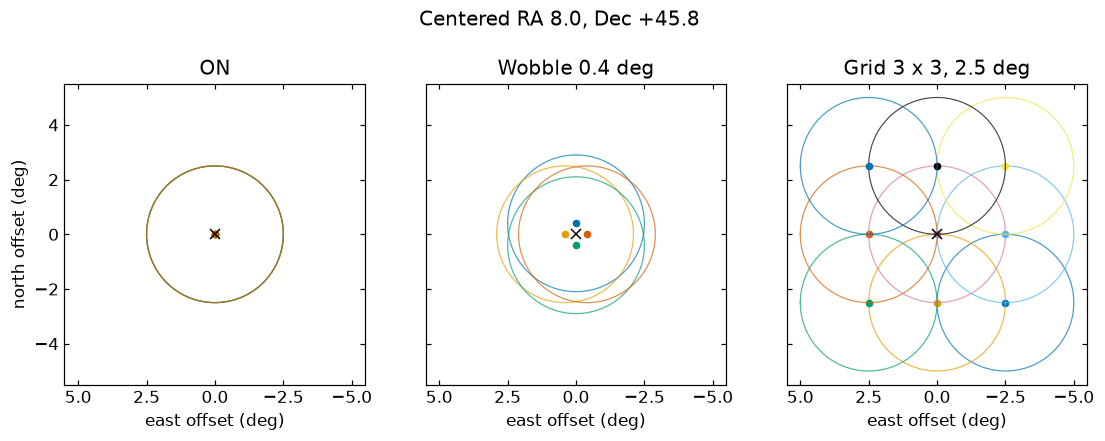

In [3]:
wob = case["sim_wobble"]
peak, t0w = wob.target(), wob.t0()
patterns = {
    "ON": pt.on(peak, t0w, 4, 1200),
    "Wobble 0.4 deg": wob.pointings(),
    "Grid 3 x 3, 2.5 deg": pt.grid(peak, t0w, 3, 2.5, 1200),
}
fig, axs = plt.subplots(1, 3, figsize=(12, 4.2), sharex=True, sharey=True)
phi = np.linspace(0, 2 * np.pi, 200)
for ax, (label, tab) in zip(axs, patterns.items()):
    off = pt.coords(tab).transform_to(SkyOffsetFrame(origin=peak))
    x, y = off.lon.wrap_at(180 * u.deg).deg, off.lat.deg      # east positive, drawn to the left
    for i, (xi, yi) in enumerate(zip(x, y)):
        ax.plot(xi + FOV_LST * np.cos(phi), yi + FOV_LST * np.sin(phi), color=COLORS[i % 8], lw=0.8, alpha=0.7)
        ax.plot(xi, yi, "o", color=COLORS[i % 8], ms=4)
    ax.plot(0, 0, "kx", ms=6)
    ax.set_title(label)
    ax.set_aspect("equal")
    ax.set_xlabel("east offset (deg)")
axs[0].invert_xaxis()
axs[0].set_ylabel("north offset (deg)")
fig.suptitle("Centered RA %.1f, Dec %+.1f" % (peak.ra.deg, peak.dec.deg))
figs.save(fig, "patterns")
plt.show()

The tilepy 2D tiling of the `sim_tiling` event (S250328ae), on its skymap. tilepy picks, for
each 20 min dark slot, the visible field centre that adds the most uncovered probability, so
the order of the tiles follows the probability along the arc. The field radius and the zenith
limit are the case's tilepy settings (they follow the extent of the simulst IRFs), not the
tilepy defaults.

In [4]:
tc = case["sim_tiling"]
tiles = tc.pointings()
t0t = tc.t0()
tset = {**pt.TILEPY_LST1, **(tc.pointing.get("settings") or {})}
FOV, ZMAX = tset["FOV"], tset["maxZenith"]   # deg: field radius and zenith limit of this case
prob, _ = read_sky_map(str(tc.skymap), moc=False, nest=True, distances=False)
nside = hp.npix2nside(len(prob))
order = np.argsort(prob)[::-1]
cl = np.empty_like(prob)
cl[order] = np.cumsum(prob[order])          # credible level of each pixel
print(f"tilepy settings of the case: field radius {FOV} deg, zenith < {ZMAX} deg")
print(f"{len(tiles)} tiles from {tiles['t_start'][0].iso} to {tiles['t_start'][-1].iso}")
print(f"tilepy probability per tile summed: {tiles['pgw'].sum():.3f}")

[cache] tilepy_2d/aee506ef8148: loaded
tilepy settings of the case: field radius 2.0 deg, zenith < 55 deg
4 tiles from 2025-03-01 00:01:00.000 to 2025-03-01 01:01:00.000
tilepy probability per tile summed: 0.973


tilepy's per-tile numbers are computed on its own grids (`HRnside` 512 for the disc sums).
As a check, the union of the tile discs is computed directly on the skymap pixels.

In [5]:
hr = hp.ud_grade(prob, 512, order_in="NESTED", order_out="NESTED", power=-2)
covered = np.zeros(hr.size, bool)
for v in hp.ang2vec(np.asarray(tiles["ra"]), np.asarray(tiles["dec"]), lonlat=True):
    covered[hp.query_disc(512, v, np.radians(FOV), nest=True)] = True
print(f"probability inside the union of the tiles: {hr[covered].sum():.3f}")

probability inside the union of the tiles: 0.973


Map of the probability density around the arc, the 50% and 90% contours, and the tiles
numbered in observing order.

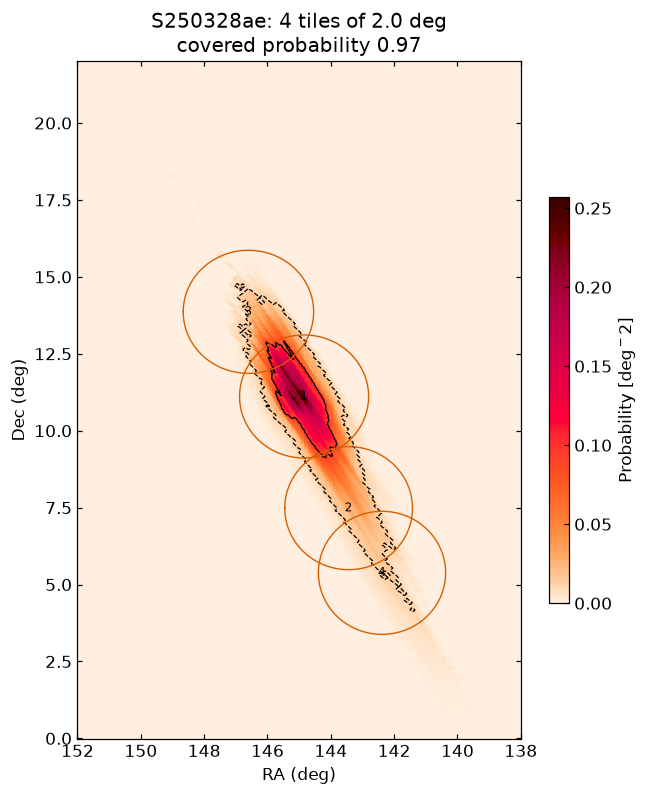

In [6]:
ra_g = np.linspace(138, 152, 551)
dec_g = np.linspace(0, 22, 951)
RA, DEC = np.meshgrid(ra_g, dec_g)
ipix = hp.ang2pix(nside, RA, DEC, nest=True, lonlat=True)
dens = prob[ipix] / hp.nside2pixarea(nside, degrees=True)
fig, ax = plt.subplots(figsize=(6.5, 8))
im = ax.pcolormesh(RA, DEC, dens, cmap="cylon", shading="auto", rasterized=True)
ax.contour(RA, DEC, cl[ipix], levels=[0.5, 0.9], colors=["k", "k"], linestyles=["-", "--"], linewidths=0.8)
for i, r in enumerate(tiles):
    ax.plot(r["ra"] + FOV * np.cos(phi) / np.cos(np.radians(r["dec"])), r["dec"] + FOV * np.sin(phi),
            color=COLORS[3], lw=0.9)
    ax.text(r["ra"], r["dec"], str(r["obs_id"]), ha="center", va="center", fontsize=8)
ax.set(xlim=(ra_g.max(), ra_g.min()), xlabel="RA (deg)", ylabel="Dec (deg)")
ax.set_title(f"S250328ae: {len(tiles)} tiles of {FOV} deg\ncovered probability {hr[covered].sum():.2f}")
fig.colorbar(im, ax=ax, label="Probability [deg$^-2$]", shrink=0.6)
figs.save(fig, "tiling_S250328ae")
plt.show()

Altitude of each pointing over the night of the simulated merger, with the Sun below -18 deg
shaded and the merger time marked. The thick segment of each curve is the run itself. The
dotted line is 40 deg zenith, the limit used to place the merger time; the dashed line on the
tiling panel is the zenith limit given to tilepy in the case config.

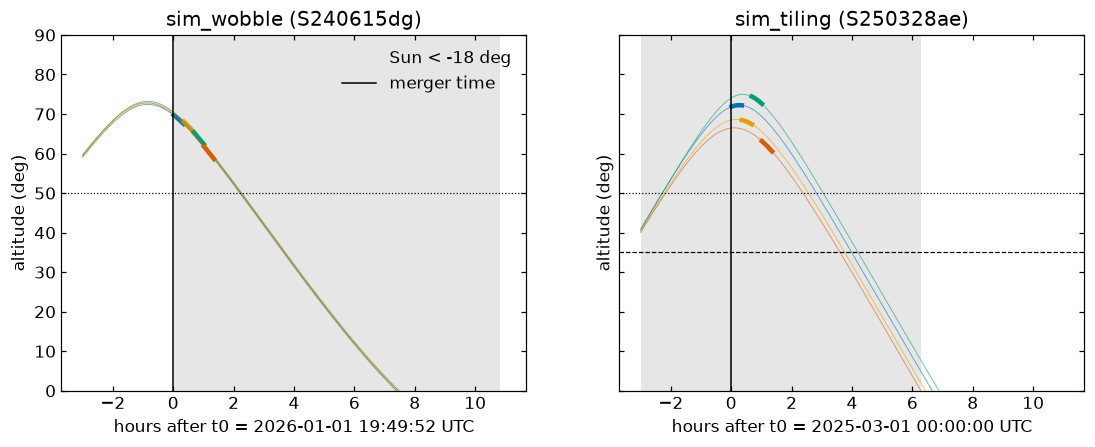

In [7]:
def night_plot(ax, tab, t0, title, zmax=None):
    t = t0 + np.linspace(-3, 11, 600) * u.h
    h = (t - t0).to_value(u.h)
    dark = eventtime.sun_altitude(t) < eventtime.SUN_DARK_DEG
    ax.fill_between(h, 0, 90, where=dark, color="0.9", lw=0, label="Sun < -18 deg")
    for i, r in enumerate(tab):
        c = SkyCoord(r["ra"] * u.deg, r["dec"] * u.deg)
        ax.plot(h, eventtime.altitude(c, t), color=COLORS[i % 8], lw=0.6, alpha=0.6)
        tr = r["t_start"] + np.linspace(0, r["duration"], 10) * u.s
        ax.plot((tr - t0).to_value(u.h), eventtime.altitude(c, tr), color=COLORS[i % 8], lw=3)
    ax.axvline(0, color="k", lw=1, label="merger time")
    ax.axhline(50, color="k", ls=":", lw=0.8)
    if zmax is not None:
        ax.axhline(90 - zmax, color="k", ls="--", lw=0.8)
    ax.set_ylim(0, 90)
    ax.set_xlabel(f"hours after t0 = {t0.iso[:19]} UTC")
    ax.set_ylabel("altitude (deg)")
    ax.set_title(title)

fig, axs = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
night_plot(axs[0], patterns["Wobble 0.4 deg"], t0w, "sim_wobble (S240615dg)")
night_plot(axs[1], tiles, t0t, "sim_tiling (S250328ae)", zmax=ZMAX)
axs[0].legend(loc="upper right")
figs.save(fig, "altitude_vs_time")
plt.show()

For each case: the merger time and its rule, the data, and the analysis region the case asks
for. The real case has no pointings yet: they will come from the observation index of the
real runs, written to the ECSV named in its config.

In [8]:
for name, c in case.items():
    try:
        tab = c.pointings()
        cen, w = c.analysis_center(tab), c.analysis_width(tab)
        plan = (f"{len(tab)} runs of {tab['duration'][0] / 60:.0f} min, first {tab['t_start'][0].iso[:19]}, "
                f"analysis centre ({cen.ra.deg:.1f}, {cen.dec.deg:+.1f}), width {w[0]:.0f} x {w[1]:.0f} deg")
    except FileNotFoundError as err:
        plan = "pointings not available yet: " + str(err).split("; ")[1]
    print(f"{name:15s} t0 {c.t0().iso[:19]} ({c.t0_mode}), data {c.data_kind}, {c.pointing['strategy']}")
    print(" " * 16 + plan)

real_S240615dg  t0 2024-06-15 11:36:20 (real), data real, real
                pointings not available yet: expected /home/jjimenezq/projects/uncertain-uls/configs/cases/real_S240615dg_pointings.ecsv (a Pointings ECSV built from the observation index of the real DL3 runs)
[cache] tilepy_2d/aee506ef8148: loaded
sim_tiling      t0 2025-03-01 00:00:00 (observable), data simulst, tilepy
                4 runs of 20 min, first 2025-03-01 00:01:00, analysis centre (144.3, +9.5), width 10 x 14 deg
sim_wobble      t0 2026-01-01 19:49:52 (observable), data simulst, wobble
                4 runs of 20 min, first 2026-01-01 19:50:52, analysis centre (8.0, +45.8), width 6 x 6 deg


The tiling arc gives a tall single analysis region (printed above). That is what the auto rule
yields for these tiles; the case config analyses the tiling field by field instead
(`analysis.fields`).

Outputs: figures `outputs/figures/0_tools/02_pointings/{patterns,tiling_S250328ae,altitude_vs_time}.{png,pdf}`;
the tilepy tiling stays in `cache/tilepy_2d/`.